<a href="https://colab.research.google.com/github/SithmiDesilva/Hallucination-Aware-AI-Framework-for-Trustworthy-Supply-Chain-Decision-Intelligence.-/blob/M5_Forecasting_Preprocessing/M5_Forecasting_Sales_Train_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================================
# NOTEBOOK 3: SALES TRAIN EVALUATION DATASET PREPROCESSING
# ============================================================================
# This notebook handles the sales_train_evaluation.csv dataset
# It's similar to validation but has 28 additional days
# ============================================================================


###  SECTION 1: SETUP AND DATA LOADING

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Load the evaluation dataset
sales_eval = pd.read_csv('/content/drive/MyDrive/IRP/M5 Forecasting dataset/sales_train_evaluation.csv')


In [5]:
print(f"\nDataset Shape: {sales_eval.shape}")


Dataset Shape: (30490, 1947)


In [6]:
# Also load validation for comparison
sales_val = pd.read_csv('/content/drive/MyDrive/IRP/M5 Forecasting dataset/sales_train_validation.csv')

In [7]:
print(f"\n--- Comparison with Validation ---")
print(f"Validation shape: {sales_val.shape}")
print(f"Evaluation shape: {sales_eval.shape}")


--- Comparison with Validation ---
Validation shape: (30490, 1919)
Evaluation shape: (30490, 1947)


In [8]:
val_day_cols = [col for col in sales_val.columns if col.startswith('d_')]
eval_day_cols = [col for col in sales_eval.columns if col.startswith('d_')]
print(f"Validation days: {len(val_day_cols)}")
print(f"Evaluation days: {len(eval_day_cols)}")
print(f"Additional days in evaluation: {len(eval_day_cols) - len(val_day_cols)}")

Validation days: 1913
Evaluation days: 1941
Additional days in evaluation: 28


### SECTION 2: INITIAL DATA EXPLORATION (BEFORE PREPROCESSING)

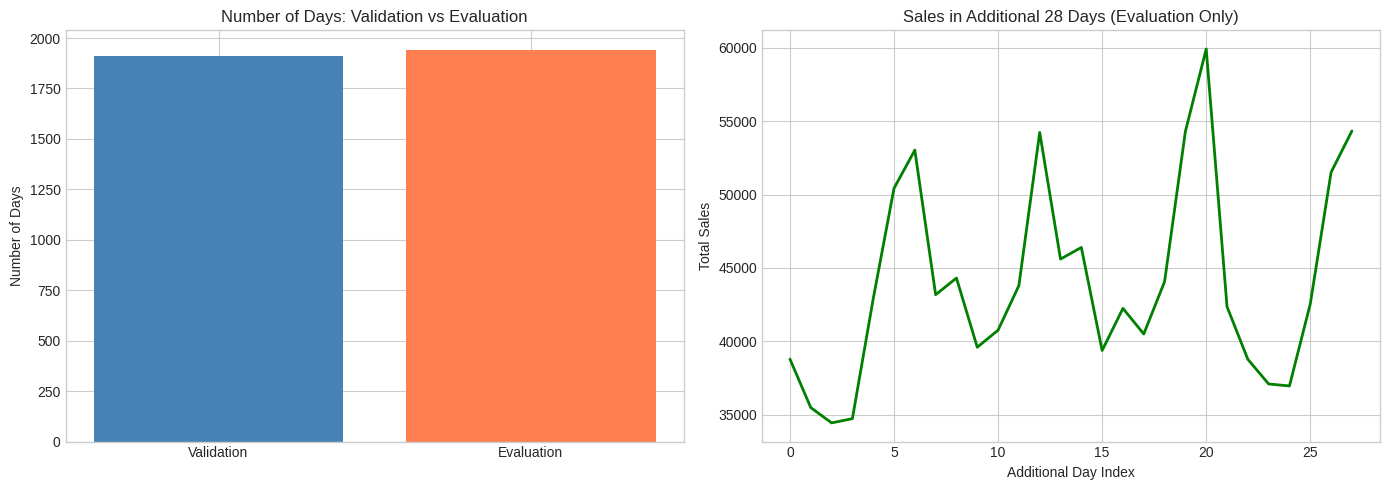

In [9]:
# Visualize the additional days
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Compare number of days
axes[0].bar(['Validation', 'Evaluation'], [len(val_day_cols), len(eval_day_cols)],
            color=['steelblue', 'coral'])
axes[0].set_ylabel('Number of Days')
axes[0].set_title('Number of Days: Validation vs Evaluation')

# Show the additional 28 days
additional_days = eval_day_cols[len(val_day_cols):]
sales_eval_additional = sales_eval[additional_days].sum()
axes[1].plot(range(len(sales_eval_additional)), sales_eval_additional.values,
             color='green', linewidth=2)
axes[1].set_xlabel('Additional Day Index')
axes[1].set_ylabel('Total Sales')
axes[1].set_title('Sales in Additional 28 Days (Evaluation Only)')

plt.tight_layout()
plt.savefig('sales_eval_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## SECTION 3: PREPROCESSING

In [11]:
# Create copy
sales_eval_processed = sales_eval.copy()

# 3.1 Split ID
print("\n--- Step 1: Splitting ID Column ---")
id_parts = sales_eval_processed['id'].str.split('_', expand=True)
id_parts.columns = ['cat_id', 'dept_id', 'item_id', 'state_id', 'store_id', 'data_type']
sales_eval_processed = pd.concat([sales_eval_processed, id_parts], axis=1)
print("ID components extracted")


--- Step 1: Splitting ID Column ---
ID components extracted


In [14]:
# 3.3 Convert day columns
print("\n--- Step 3: Day Column Conversion ---")

# Loop through each day column (e.g., 'd_1', 'd_2', ...) to optimize memory usage
for col in eval_day_cols:
    # Convert string values to numeric types, forcing any parsing errors to NaN
    sales_eval_processed[col] = pd.to_numeric(sales_eval_processed[col], errors='coerce')
    # Cast the numeric values to 16-bit integers to significantly reduce the dataframe memory footprint
    sales_eval_processed[col] = sales_eval_processed[col].astype('int16')
print(f"Day columns converted to int16")

# Show a preview of the converted columns
print("\nSample of converted day columns:")
# Display the first 5 rows of the first 5 day columns as a verification step
display(sales_eval_processed[eval_day_cols[:5]].head())

print("\nData types of sample day columns:")
# Print the updated data types to verify they have been successfully cast to int16
print(sales_eval_processed[eval_day_cols[:5]].dtypes)


--- Step 3: Day Column Conversion ---
Day columns converted to int16

Sample of converted day columns:


,d_1,d_2,d_3,d_4,d_5
0,0,0,0,0,0
1,0,0,0,0,0
2,0,0,0,0,0
3,0,0,0,0,0
4,0,0,0,0,0



Data types of sample day columns:
d_1    int16
d_2    int16
d_3    int16
d_4    int16
d_5    int16
dtype: object


In [16]:
# 3.4 Calculate summary statistics
print("\n--- Step 4: Summary Statistics ---")
summary_stats = pd.DataFrame({
    'total_sales': sales_eval_processed[eval_day_cols].sum(axis=1),
    'mean_sales': sales_eval_processed[eval_day_cols].mean(axis=1),
    'std_sales': sales_eval_processed[eval_day_cols].std(axis=1),
    'min_sales': sales_eval_processed[eval_day_cols].min(axis=1),
    'max_sales': sales_eval_processed[eval_day_cols].max(axis=1),
    'zero_days': (sales_eval_processed[eval_day_cols] == 0).sum(axis=1),
    'non_zero_days': (sales_eval_processed[eval_day_cols] > 0).sum(axis=1),
    'zero_ratio': (sales_eval_processed[eval_day_cols] == 0).sum(axis=1) / len(eval_day_cols)
})
sales_eval_processed = pd.concat([sales_eval_processed, summary_stats], axis=1)
print("Summary statistics added")

# Display the preview of the calculated summary statistics
print("\nPreview of calculated summary statistics:")
display(summary_stats.head())

print("\nOverall statistics summary:")
display(summary_stats.describe())


--- Step 4: Summary Statistics ---
Summary statistics added

Preview of calculated summary statistics:


,total_sales,mean_sales,std_sales,min_sales,max_sales,zero_days,non_zero_days,zero_ratio
0,633,0.326121,0.708041,0,5,1505,436,0.775374
1,500,0.257599,0.568594,0,5,1533,408,0.789799
2,309,0.159196,0.501446,0,6,1712,229,0.882020
3,3337,1.719217,1.986809,0,15,625,1316,0.321999
4,1888,0.972694,1.292634,0,9,958,983,0.493560



Overall statistics summary:


,total_sales,mean_sales,std_sales,min_sales,max_sales,zero_days,non_zero_days,zero_ratio
count,30490.000000,30490.000000,30490.000000,30490.0,30490.000000,30490.000000,30490.000000,30490.000000
mean,2195.053231,1.130888,1.504578,0.0,13.530764,1319.836635,621.163365,0.679978
std,5290.421671,2.725617,2.299731,0.0,22.180518,433.631478,433.631478,0.223406
min,15.000000,0.007728,0.090440,0.0,1.000000,3.000000,12.000000,0.001546
25%,366.000000,0.188563,0.527984,0.0,5.000000,1038.000000,262.000000,0.534776
50%,868.000000,0.447192,0.887602,0.0,8.000000,1423.000000,518.000000,0.733127
75%,2072.000000,1.067491,1.569712,0.0,14.000000,1679.000000,903.000000,0.865018
max,253859.000000,130.787738,107.911678,0.0,763.000000,1929.000000,1938.000000,0.993818


## SECTION 4: OUTLIER DETECTION

In [20]:
def detect_eval_outliers(df, day_cols):
    """Detect and handle outliers, printing useful metrics and insights."""
    df_clean = df.copy()

    print("\n=== OUTLIER ANALYSIS & PROCESSING ===")
    print(f"Analyzing {len(day_cols)} days across {len(df)} series ({len(day_cols) * len(df)} total data points)")
    print("-" * 50)

    total_outliers = 0
    total_elements = len(day_cols) * len(df)

    # Track metrics before capping to provide insights
    original_max = df[day_cols].max().max()
    original_mean = df[day_cols].mean().mean()

    for col in day_cols:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 3 * IQR
        upper_bound = Q3 + 3 * IQR

        # Count outliers
        outliers_count = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()
        if outliers_count > 0:
            total_outliers += outliers_count
            df_clean[col] = df_clean[col].clip(lower_bound, upper_bound)

    outlier_pct = (total_outliers / total_elements) * 100
    print(f"1. IQR Method Outlier Detection:")
    print(f"   - Total outliers capped: {total_outliers:,}")
    print(f"   - Percentage of total data points capped: {outlier_pct:.4f}%")

    # Negative sales check
    print("\n2. Negative Sales Check:")
    negative = (df_clean[day_cols] < 0).sum().sum()
    if negative > 0:
        df_clean[day_cols] = df_clean[day_cols].clip(lower=0)
        print(f"   - Fixed {negative:,} negative values")
    else:
        print("   - ✅ No negative sales detected")

    # Post-processing comparisons
    new_max = df_clean[day_cols].max().max()
    new_mean = df_clean[day_cols].mean().mean()

    print("\n3. Impact Assessment Summary:")
    print(f"   - Maximum single-day sales value: reduced from {original_max} to {new_max}")
    print(f"   - Overall mean sales value: changed from {original_mean:.4f} to {new_mean:.4f}")


    df_clean['outlier_flag'] = 0
    return df_clean

sales_eval_cleaned = detect_eval_outliers(sales_eval_processed, eval_day_cols)


=== OUTLIER ANALYSIS & PROCESSING ===
Analyzing 1941 days across 30490 series (59181090 total data points)
--------------------------------------------------
1. IQR Method Outlier Detection:
   - Total outliers capped: 5,432,638
   - Percentage of total data points capped: 9.1797%

2. Negative Sales Check:
   - ✅ No negative sales detected

3. Impact Assessment Summary:
   - Maximum single-day sales value: reduced from 763 to 8
   - Overall mean sales value: changed from 1.1309 to 0.6249


## SECTION 5: VISUALIZATION AFTER PREPROCESSING

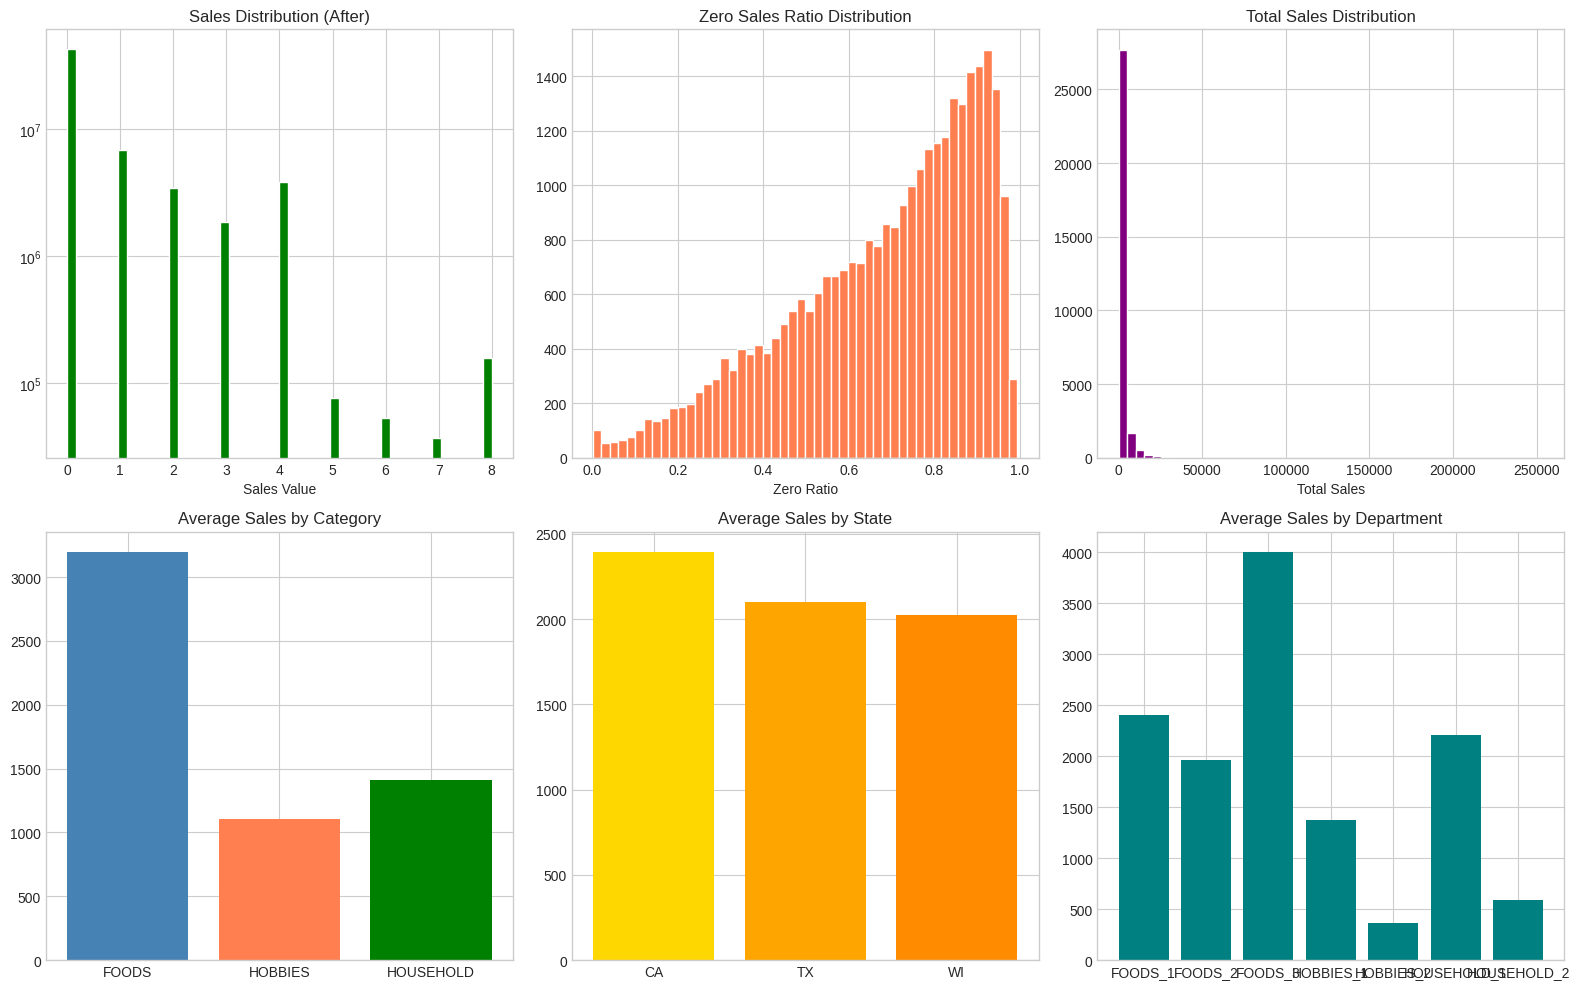

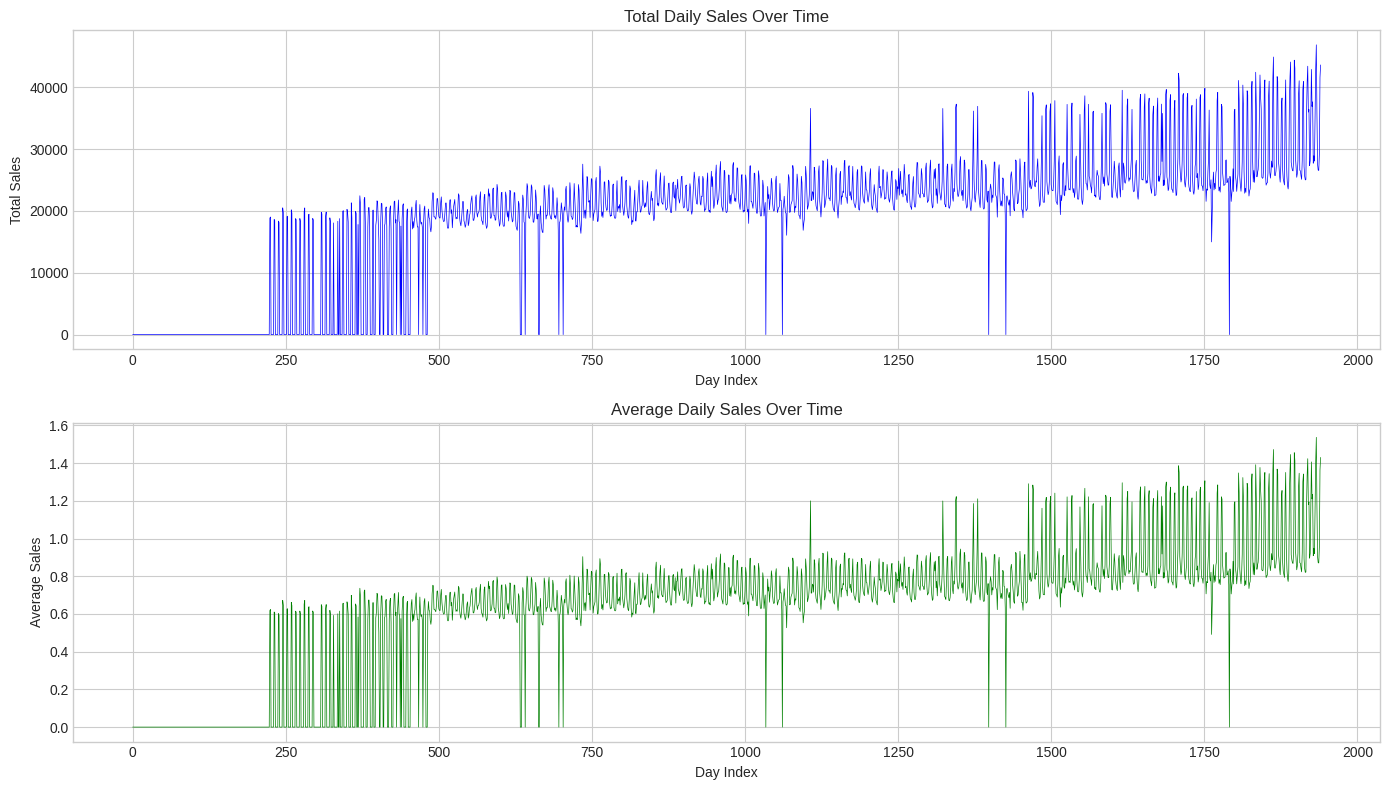

In [22]:
# Remove duplicate columns if the cells were run multiple times
sales_eval_cleaned = sales_eval_cleaned.loc[:, ~sales_eval_cleaned.columns.duplicated()]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Sales distribution
sample_sales = sales_eval_cleaned[eval_day_cols].values.flatten()
axes[0, 0].hist(sample_sales, bins=50, color='green', edgecolor='white')
axes[0, 0].set_xlabel('Sales Value')
axes[0, 0].set_title('Sales Distribution (After)')
axes[0, 0].set_yscale('log')

# Zero ratio
axes[0, 1].hist(sales_eval_cleaned['zero_ratio'], bins=50, color='coral', edgecolor='white')
axes[0, 1].set_xlabel('Zero Ratio')
axes[0, 1].set_title('Zero Sales Ratio Distribution')

# Total sales
axes[0, 2].hist(sales_eval_cleaned['total_sales'], bins=50, color='purple', edgecolor='white')
axes[0, 2].set_xlabel('Total Sales')
axes[0, 2].set_title('Total Sales Distribution')

# By category
cat_sales = sales_eval_cleaned.groupby('cat_id')['total_sales'].mean()
axes[1, 0].bar(cat_sales.index.astype(str), cat_sales.values, color=['steelblue', 'coral', 'green'])
axes[1, 0].set_title('Average Sales by Category')

# By state
state_sales = sales_eval_cleaned.groupby('state_id')['total_sales'].mean()
axes[1, 1].bar(state_sales.index.astype(str), state_sales.values, color=['gold', 'orange', 'darkorange'])
axes[1, 1].set_title('Average Sales by State')

# By department
dept_sales = sales_eval_cleaned.groupby('dept_id')['total_sales'].mean()
axes[1, 2].bar(dept_sales.index.astype(str), dept_sales.values, color='teal')
axes[1, 2].set_title('Average Sales by Department')

plt.tight_layout()
plt.savefig('sales_eval_after_preprocessing.png', dpi=150, bbox_inches='tight')
plt.show()

# Time series
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

daily_total = sales_eval_cleaned[eval_day_cols].sum()
axes[0].plot(range(len(daily_total)), daily_total.values, color='blue', linewidth=0.5)
axes[0].set_xlabel('Day Index')
axes[0].set_ylabel('Total Sales')
axes[0].set_title('Total Daily Sales Over Time')

daily_avg = sales_eval_cleaned[eval_day_cols].mean()
axes[1].plot(range(len(daily_avg)), daily_avg.values, color='green', linewidth=0.5)
axes[1].set_xlabel('Day Index')
axes[1].set_ylabel('Average Sales')
axes[1].set_title('Average Daily Sales Over Time')

plt.tight_layout()
plt.savefig('sales_eval_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()